In [21]:
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt

In [22]:

import numpy as np
import geopandas as gpd
import pandas as pd
from solaris.eval.iou import calculate_iou
from pathlib import Path
import os, sys

# adding logging
import logging
log = logging.getLogger(__name__)
log.addHandler(logging.NullHandler())

In [23]:
# #################################################################
# #
# # created for ramp project, August 2022
# # Author: carolyn.johnston@dev.global
# #
# #################################################################


# import numpy as np
# import geopandas as gpd
# import pandas as pd
# from solaris.eval.iou import calculate_iou
# from pathlib import Path
# import os, sys

# # adding logging
# import logging
# log = logging.getLogger(__name__)
# log.addHandler(logging.NullHandler())

# def get_iou_df(test_df, truth_df,iou_thresh=0.5, remove_matching_element=True):
#     '''
#     returns dataframe of test polygons with a column 'match_id' added
#     its value for each test polygon is the id of the best match in the truth dataset,
#     or -1 if no match was found
#     '''
#     test_result_list = []

#     # we need to use a copy of the truth data, as 
#     # matches will be removed during processing.
#     copy_truth_df = truth_df.copy(deep=True)

#     # insert columns 'match_id' and 'best_iou_score' into the test dataframe
#     test_df = test_df.assign(match_id=pd.array(np.full(len(test_df), -1), dtype="int32"))
#     test_df = test_df.assign(best_iou_score=pd.array(np.full(len(test_df), np.nan), dtype="float32"))

#     test_df = test_df.reset_index()  # make sure indexes pair with number of rows
#     for index, row in test_df.iterrows():
#         test_poly = row['geometry']

#         # get an iou dataframe containing all the rows in the truth data 
#         # with polygons that overlap the test polygon
#         # this may be empty but iou_df should never be None
#         # iou_df = calculate_iou(test_poly, copy_truth_df)
#         iou_df = calculate_iou(
#             test_poly,
#             copy_truth_df.geometry,
#             return_iou=True
#         )
#         iou_df = pd.DataFrame(
#             iou_df,
#             index=copy_truth_df.index,
#             columns=["iou_score"]
#         )
#         if len(iou_df) == 0:
#             row['match_id'] = -1
#             row['best_iou_score'] = np.nan
#             test_result_list.append(row)
#             continue
#         max_iou_row = iou_df.loc[iou_df['iou_score'].idxmax(axis=0, skipna=True)]
#         best_iou_score = max_iou_row['iou_score']
#         if max_iou_row is None or best_iou_score < iou_thresh:
#             row['match_id'] = -1
#             row['best_iou_score'] = np.nan
#             test_result_list.append(row)
#             continue
#         row['match_id'] = int(max_iou_row.name)
#         row['best_iou_score'] = best_iou_score
#         if remove_matching_element:
#             copy_truth_df.drop(max_iou_row.name, axis=0, inplace=True)
#         test_result_list.append(row)

#     return  gpd.GeoDataFrame(test_result_list)

# def get_iou_accuracy_metrics(test_data, truth_data, size_threshold=None, iou_threshold=0.5):
#     '''
#     returns dictionary containing accuracy metrics

#     test_data: geopandas data frame containing proposal data
#     truth_data: geopandas data frame containing truth data
#     -- > Both the truth data and test data frames are assumed to have an 'id' field
    
#     threshold (float, 0<threshold<1): above which value of IoU a detection is considered to have occurred
#     '''

#     f_truth_data = truth_data
#     f_test_data = test_data

#     # apply filtering
#     if size_threshold:
#         if "area_m2" in truth_data.keys() and "area_m2" in test_data.keys():
#             f_truth_data = truth_data[truth_data["area_m2"] >= size_threshold]
#             f_test_data = test_data[test_data["area_m2"] >= size_threshold]
#         else:
#             log.warning("No area_m2 attribute on buildings: cannot apply building size filtering")
#     n_truth = len(f_truth_data)
#     n_test = len(f_test_data)
#     if n_test == 0 or n_truth==0:
#         metrics = {
#             'n_detections': n_test, 
#             'n_truth':n_truth, 
#             'true_pos':0,
#             'false_pos':n_test,
#             'false_neg':n_truth,
#             'recall': 0 if n_truth != 0 else None,
#             'precision': 0 if n_test != 0 else None,
#             'F1': None
#         }
#         return metrics

#     iou_df = get_iou_df(f_test_data, f_truth_data, iou_thresh=iou_threshold)
#     assert len(f_truth_data) == n_truth
#     true_positives = iou_df[iou_df['match_id'] != -1]
#     n_matched = len(true_positives)
#     recall = n_matched/n_truth
#     precision = n_matched/n_test
#     F1 = 2*recall*precision/(recall+precision) if recall+precision != 0 else 0
#     metrics = {
#         'n_detections': n_test, 
#         'n_truth':n_truth, 
#         'true_pos':n_matched,
#         'false_pos':n_test - n_matched,
#         'false_neg':n_truth - n_matched,
#         'recall':recall,
#         'precision':precision,
#         'F1':F1
#     }
#     return metrics


In [24]:
# pathes

holdout_bboxs_path = "/home/jovyan/work/training-models/south_afghanistan/holdout/holdout_bbox.gpkg"
truth_labels_path ="/home/jovyan/work/training-models/south_afghanistan/holdout/labels" 

preds_dict = { 
         "preds_path_v3" : "/home/jovyan/work/predictions/south_afg/v1/geojson/predicted_buildings.geojson",
        }

imgs_path = "/home/jovyan/work/training-models/south_afghanistan/holdout/imgs"

In [25]:
import geopandas as gpd

def calculate_iou(geom1, geom2):
    """
    Calculate Intersection over Union (IoU) between two geometries.

    Parameters:
    geom1, geom2: shapely.geometry objects (or GeoSeries with a single geometry)

    Returns:
    iou: float, value between 0 and 1
    """
    # Ensure the inputs are not empty
    # if geom1.is_empty or geom2.is_empty:
    #     return 0.0

   # Union of geometries
    union = geom1.union(geom2.unary_union)
    # Intersection of geometries
    intersection = geom1.intersection(geom2.unary_union)
    # Areas
    intersection_area = intersection.area
    union_area = union.area
    
    # Handle edge case to avoid division by zero
    if union_area == 0:
        return 0.0

    iou = intersection_area / union_area
    
    
    return iou, union , intersection


In [26]:

# def get_iou_df(test_df, truth_df,iou_thresh=0.5, remove_matching_element=True):
#     '''
#     returns dataframe of test polygons with a column 'match_id' added
#     its value for each test polygon is the id of the best match in the truth dataset,
#     or -1 if no match was found
#     '''
#     test_result_list = []

#     # we need to use a copy of the truth data, as 
#     # matches will be removed during processing.
#     copy_truth_df = truth_df.copy(deep=True)

#     # insert columns 'match_id' and 'best_iou_score' into the test dataframe
#     test_df = test_df.assign(match_id=pd.array(np.full(len(test_df), -1), dtype="int32"))
#     test_df = test_df.assign(best_iou_score=pd.array(np.full(len(test_df), np.nan), dtype="float32"))

#     test_df = test_df.reset_index()  # make sure indexes pair with number of rows
#     for index, row in test_df.iterrows():
#         test_poly = row['geometry']

#         # get an iou dataframe containing all the rows in the truth data 
#         # with polygons that overlap the test polygon
#         # this may be empty but iou_df should never be None
#         iou_df = calculate_iou(test_poly, copy_truth_df)
#         if len(iou_df) == 0:
#             row['match_id'] = -1
#             row['best_iou_score'] = np.nan
#             test_result_list.append(row)
#             continue
#         max_iou_row = iou_df.loc[iou_df['iou_score'].idxmax(axis=0, skipna=True)]
#         best_iou_score = max_iou_row['iou_score']
#         if max_iou_row is None or best_iou_score < iou_thresh:
#             row['match_id'] = -1
#             row['best_iou_score'] = np.nan
#             test_result_list.append(row)
#             continue
#         row['match_id'] = int(max_iou_row.name)
#         row['best_iou_score'] = best_iou_score
#         if remove_matching_element:
#             copy_truth_df.drop(max_iou_row.name, axis=0, inplace=True)
#         test_result_list.append(row)

#     return  gpd.GeoDataFrame(test_result_list)

In [27]:
def get_iou_accuracy_metrics(test_data, truth_data, size_threshold=None, iou_threshold=0.5):
    '''
    returns dictionary containing accuracy metrics

    test_data: geopandas data frame containing proposal data
    truth_data: geopandas data frame containing truth data
    -- > Both the truth data and test data frames are assumed to have an 'id' field
    
    threshold (float, 0<threshold<1): above which value of IoU a detection is considered to have occurred
    '''

    f_truth_data = truth_data
    f_test_data = test_data

    # apply filtering
    if size_threshold:
        if "area_m2" in truth_data.keys() and "area_m2" in test_data.keys():
            f_truth_data = truth_data[truth_data["area_m2"] >= size_threshold]
            f_test_data = test_data[test_data["area_m2"] >= size_threshold]
        else:
            log.warning("No area_m2 attribute on buildings: cannot apply building size filtering")
    n_truth = len(f_truth_data)
    n_test = len(f_test_data)
    if n_test == 0 or n_truth==0:
        metrics = {
            'n_detections': n_test, 
            'n_truth':n_truth, 
            'true_pos':0,
            'false_pos':n_test,
            'false_neg':n_truth,
            'recall': 0 if n_truth != 0 else None,
            'precision': 0 if n_test != 0 else None,
            'F1': None
        }
        return metrics

    iou_df = get_iou_df(f_test_data, f_truth_data, iou_thresh=iou_threshold)
    assert len(f_truth_data) == n_truth
    true_positives = iou_df[iou_df['match_id'] != -1]
    n_matched = len(true_positives)
    recall = n_matched/n_truth
    precision = n_matched/n_test
    F1 = 2*recall*precision/(recall+precision) if recall+precision != 0 else 0
    metrics = {
        'n_detections': n_test, 
        'n_truth':n_truth, 
        'true_pos':n_matched,
        'false_pos':n_test - n_matched,
        'false_neg':n_truth - n_matched,
        'recall':recall,
        'precision':precision,
        'F1':F1
    }
    return metrics


In [28]:
def get_iou_df(test_df, truth_df, iou_thresh=0.5, remove_matching_element=True):
    test_result_list = []
    copy_truth_df = truth_df.copy(deep=True)

    test_df = test_df.assign(match_id=-1, best_iou_score=np.nan)
    test_df = test_df.reset_index()

    for index, row in test_df.iterrows():
        test_poly = row['geometry']

        # Compute IoU for each truth polygon
        iou_scores = copy_truth_df.geometry.apply(
            lambda g: test_poly.intersection(g).area / test_poly.union(g).area
            if test_poly.union(g).area != 0 else 0
        )

        iou_df = pd.DataFrame({"iou_score": iou_scores}, index=copy_truth_df.index)

        if len(iou_df) == 0:
            test_result_list.append(row)
            continue

        max_iou_idx = iou_df['iou_score'].idxmax()
        best_iou_score = iou_df.loc[max_iou_idx, 'iou_score']

        if best_iou_score < iou_thresh:
            test_result_list.append(row)
            continue

        row['match_id'] = int(max_iou_idx)
        row['best_iou_score'] = best_iou_score

        if remove_matching_element:
            copy_truth_df.drop(max_iou_idx, inplace=True)

        test_result_list.append(row)

    return gpd.GeoDataFrame(test_result_list)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


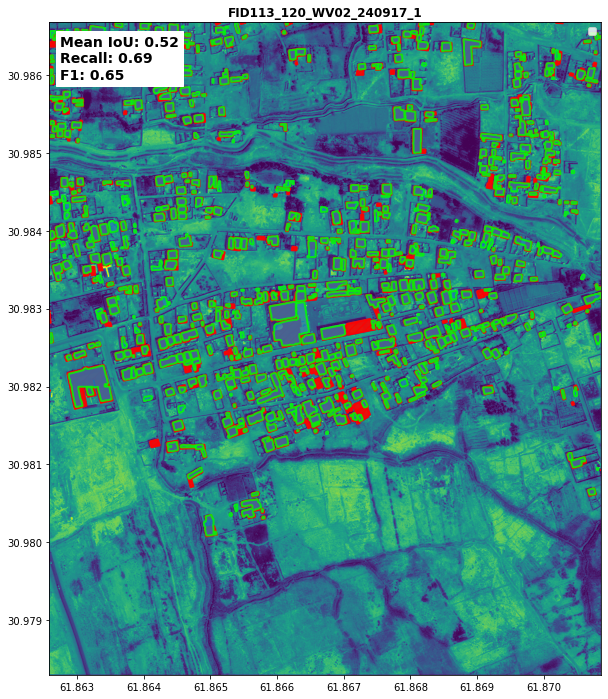

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


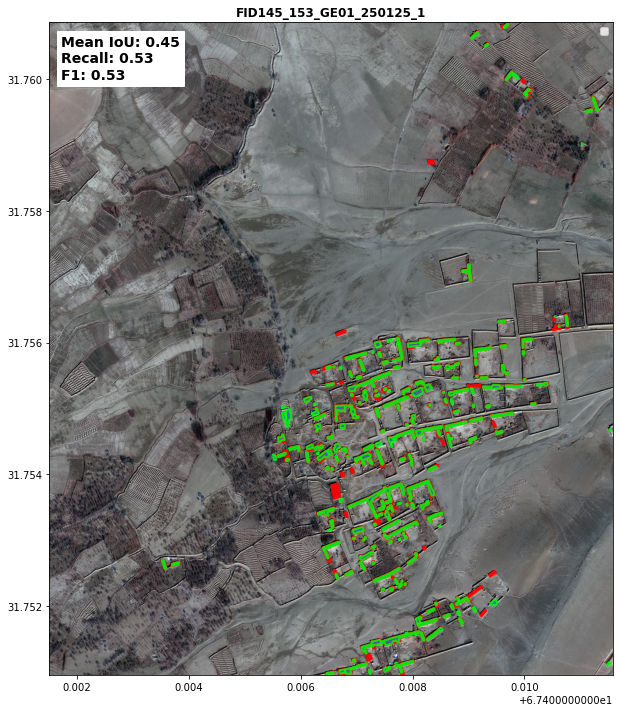

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


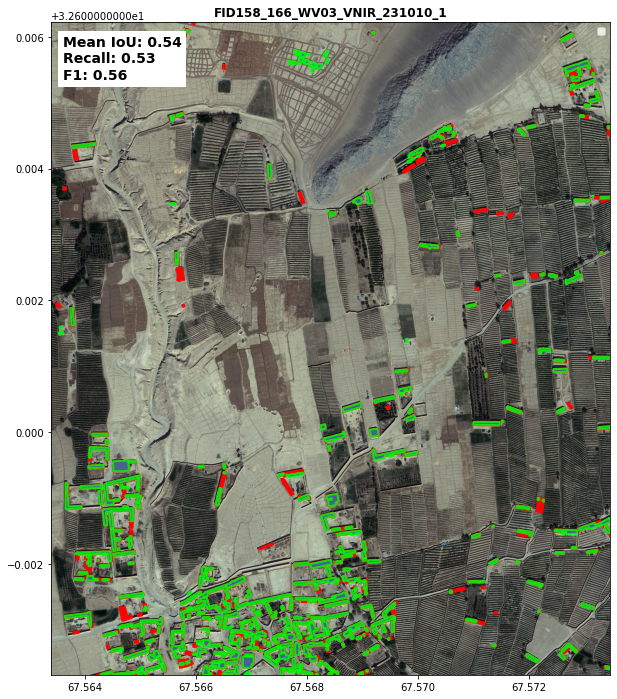

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


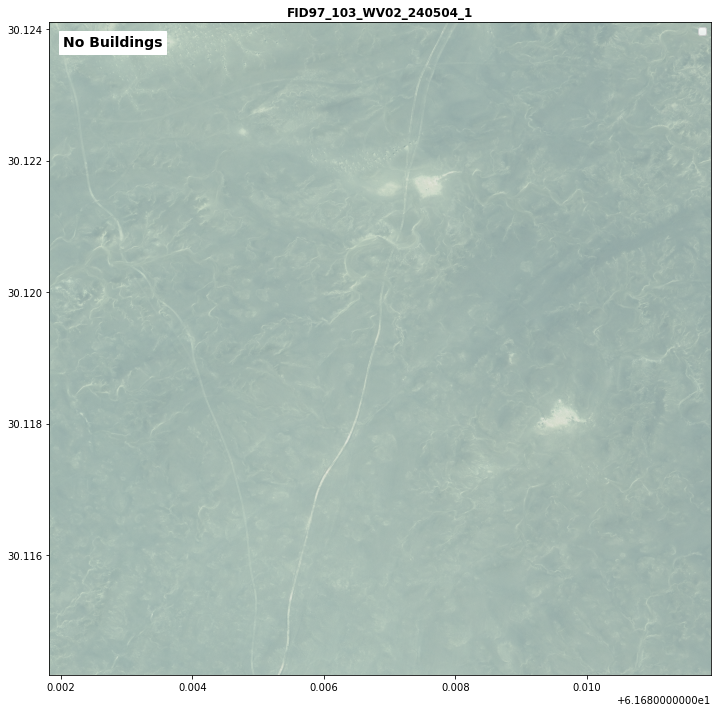

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


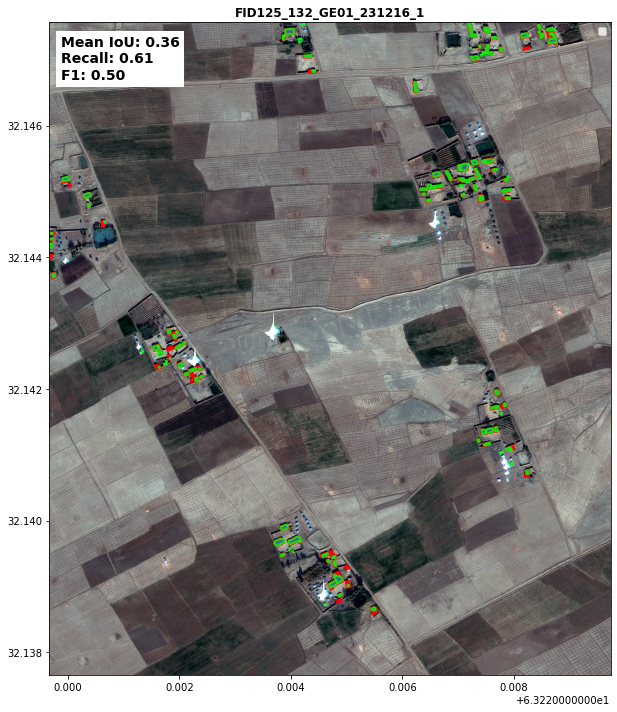

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


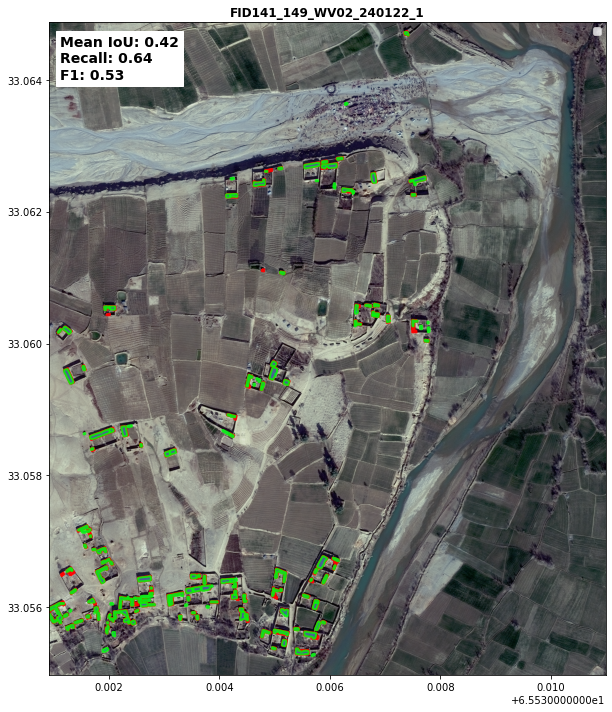

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


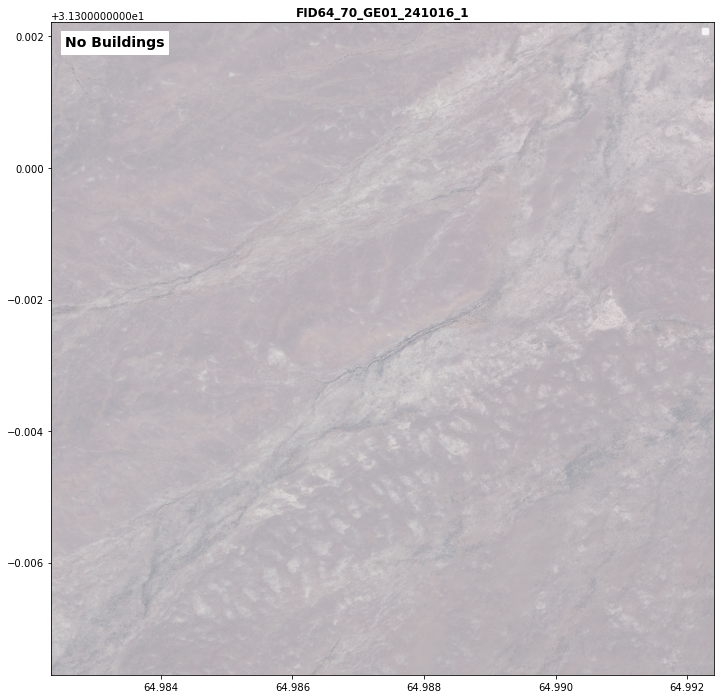

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


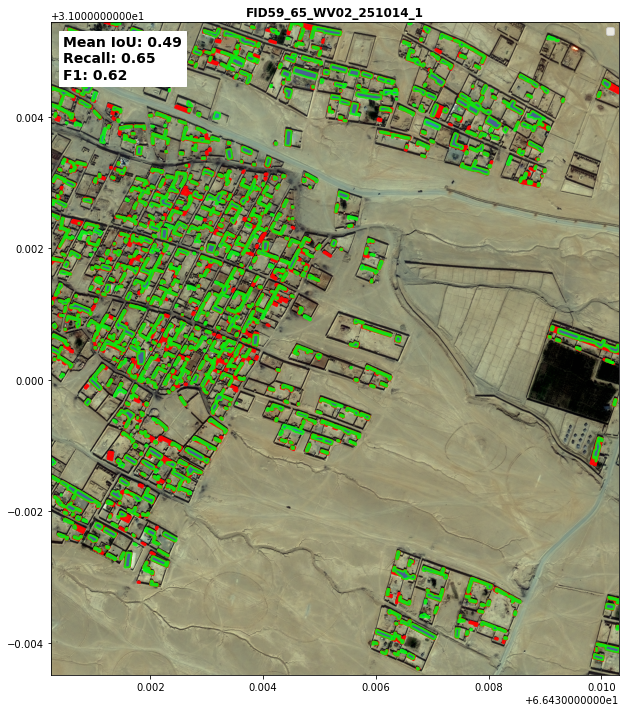

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


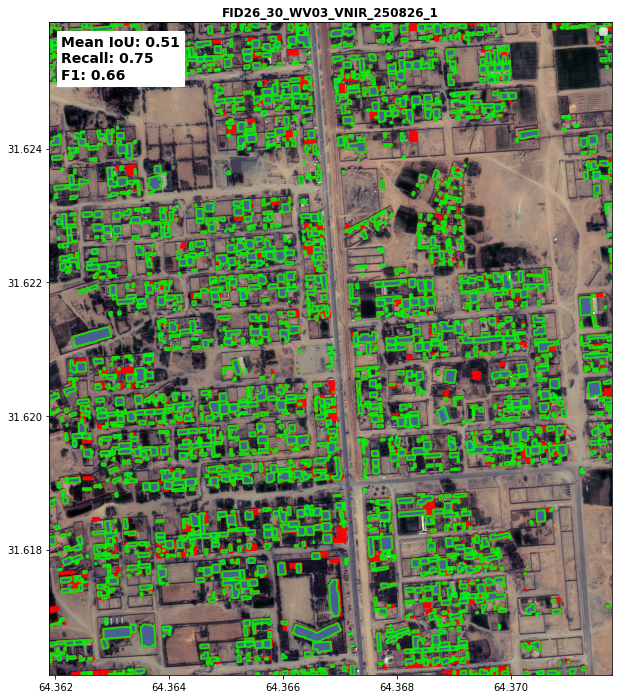

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


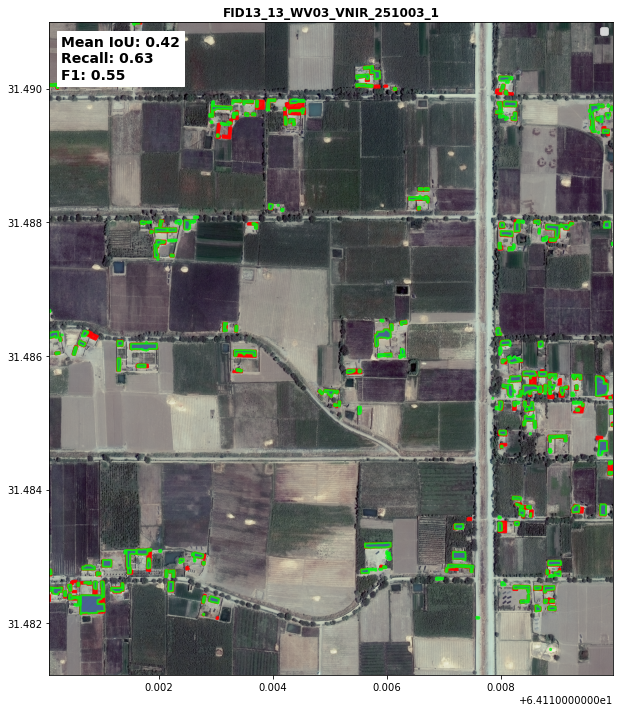

In [34]:

import os


bboxes = gpd.read_file(holdout_bboxs_path)
preds = gpd.read_file(preds_dict["preds_path_v3"])

# Lists to store metrics per image
n_detections = []
n_truth = []
n_truepos = []
n_falsepos = []
n_falseneg = []
precision_list = []
recall_list = []
f1_list = []
overall_iou_list = []

iou_threshold = 0.5  # set IoU threshold

results_list = []  # store all metrics

for index, row in bboxes.iterrows():
    
    img_name = row['path'].split('/')[-1].split('.tif')[0]
    img_path = os.path.join(imgs_path, img_name + ".tif")
    
    # Load labels
    label_path_name = os.path.join(truth_labels_path, img_name + '.geojson')
    label = gpd.read_file(label_path_name)
    
    clip_preds = preds.clip(row.geometry)
    
    # Compute metrics
    metrics = get_iou_accuracy_metrics(clip_preds, label, iou_threshold=iou_threshold)
    
    # Ensure metrics are numbers
    recall = metrics['recall'] if metrics['recall'] is not None else 0
    F1 = metrics['F1'] if metrics['F1'] is not None else 0
    
    # Compute IoU per polygon safely
    all_ious = []
    if len(clip_preds) == 0 or len(label) == 0:
        overall_iou = 0
    else:
        for idx, pred in clip_preds.iterrows():
            ious = label.geometry.apply(
                lambda g: pred.geometry.intersection(g).area / pred.geometry.union(g).area
                if pred.geometry.union(g).area != 0 else 0
            )
            all_ious.append(ious.max())
        overall_iou = np.mean(all_ious) if all_ious else 0

    # Save metrics
    results_list.append({
        "img_name": img_name,
        "n_detections": metrics['n_detections'],
        "n_truth": metrics['n_truth'],
        "true_pos": metrics['true_pos'],
        "false_pos": metrics['false_pos'],
        "false_neg": metrics['false_neg'],
        "precision": metrics['precision'],
        "recall": recall,
        "F1": F1,
        "mean_iou_all": overall_iou
    })
    
    # Start plotting
    fig, ax = plt.subplots(figsize=(12, 12))
    with rasterio.open(img_path) as src:
        if label.crs != src.crs:
            label = label.to_crs(src.crs)
            clip_preds = clip_preds.to_crs(src.crs)
        show(src, ax=ax, title=img_name)
    
    if len(label) == 0 and len(clip_preds) == 0:
        # No buildings in either
        metrics_text = "No Buildings"
    else:
        # Metrics text
        metrics_text = f"Mean IoU: {overall_iou:.2f}\nRecall: {recall:.2f}\nF1: {F1:.2f}"
    
    # Plot polygons if they exist
    if len(label) > 0:
        label.plot(
            ax=ax,
            facecolor="red",
            edgecolor="red",
            hatch="///",
            linewidth=2,
            alpha=0.9,
            label="Ground truth"
        )
    if len(clip_preds) > 0:
        clip_preds.plot(
            ax=ax,
            facecolor=None,
            edgecolor="lime",
            linewidth=2,
            alpha=0.8,
            label="Predictions"
        )
    
    # Add text
    ax.text(
        0.02, 0.98, metrics_text,
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        color='black',
        backgroundcolor='white',
        verticalalignment='top'
    )
    
    ax.legend()
    plt.show()

# Final DataFrame
results_df = pd.DataFrame(results_list)


In [35]:
n_falsepos

[]

In [21]:
iou_df

,index,value,image_id,polyid,area_m2,perim_m,geometry,match_id,best_iou_score
0,1715,1.0,tmp_chip_86.429264_26.637309.pred.tif,1986,15.531005,14.274621,"POLYGON ((86.42974 26.63659, 86.42974 26.63659...",-1,NaN
1,1881,1.0,tmp_chip_86.430266_26.639312.pred.tif,2003,129.390328,45.481385,"POLYGON ((86.43075 26.63924, 86.43075 26.63924...",28,0.876375
2,1883,1.0,tmp_chip_86.431267_26.639312.pred.tif,2016,103.972398,44.616627,"POLYGON ((86.43173 26.63936, 86.43173 26.63936...",0,0.556830
3,1739,1.0,tmp_chip_86.432268_26.640313.pred.tif,2023,125.435586,53.151064,"POLYGON ((86.43231 26.63949, 86.43231 26.63949...",2,0.558298
4,1740,1.0,tmp_chip_86.432268_26.640313.pred.tif,2024,123.255334,51.093903,"POLYGON ((86.43251 26.63956, 86.43251 26.63956...",-1,NaN
5,1738,1.0,tmp_chip_86.432268_26.640313.pred.tif,2022,19.264223,16.399422,"POLYGON ((86.43248 26.63957, 86.43248 26.63957...",-1,NaN
6,1737,1.0,tmp_chip_86.432268_26.640313.pred.tif,2021,110.341377,46.241675,"POLYGON ((86.43231 26.63958, 86.43231 26.63958...",-1,NaN
7,1736,1.0,tmp_chip_86.432268_26.640313.pred.tif,2020,30.865776,20.345010,"POLYGON ((86.43228 26.63968, 86.43228 26.63968...",3,0.761239
8,1720,1.0,tmp_chip_86.429264_26.640313.pred.tif,1993,29.906595,20.251615,"POLYGON ((86.43015 26.63968, 86.43015 26.63968...",8,0.560477
9,1719,1.0,tmp_chip_86.429264_26.640313.pred.tif,1992,59.155780,30.123685,"POLYGON ((86.43009 26.63971, 86.43009 26.63971...",7,0.847581


In [ ]:
    n_detections.append(metrics['n_detections'])
    n_truth.append(metrics['n_truth'])
    n_truepos.append(metrics['true_pos'])
    n_falsepos.append(metrics['false_pos'])
    n_falseneg.append(metrics['false_neg'])
    precision_list.append(metrics['precision'])
    recall_list.append(metrics['recall'])
    f1_list.append(metrics['F1'])

In [26]:
metrics

{'n_detections': 32,
 'n_truth': 30,
 'true_pos': 20,
 'false_pos': 12,
 'false_neg': 10,
 'recall': 0.6666666666666666,
 'precision': 0.625,
 'F1': 0.6451612903225806}

In [82]:
metrices = [n_detections ,n_truth ,n_truepos ,n_falsepos,n_falseneg,precision_list ,
            recall_list,f1_list,overall_iou_list]

In [84]:
for m in metrices:
    print(len(m))

23
23
23
23
23
23
23
23
23


In [92]:
df = pd.DataFrame(metrices).T

df.columns = ["n_detections" ,"n_truth" ,"n_truepos" ,
                                  "n_falsepos","n_falseneg","precision_list" ,
            "recall_list","f1_list","overall_iou_list"]
df.to_csv("/home/jovyan/work/training-models/nepal/Nepal_b7_2025/v3/B7_V3_015_holdout.csv")

In [68]:
iou[0]

0.7061291942798165

In [48]:
calculate_iou(label, clip_preds)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [ ]:
glob.glob()

In [1]:
import geopandas as gpd

In [2]:
gdf = gpd.read_file("/home/jovyan/work/predictions/south_afg/v1/run3_04/geojson/predicted_buildings.geojson")

In [4]:
gdf.to_file("/home/jovyan/work/predictions/south_afg/v1/run3_04/geojson/predicted_buildings.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,
